# Image Segmentation

**Source:** https://labs.acme.byu.edu/Volume1/ImageSegmentation/ImageSegmentation.html

Treat each pixel of an image as a node in a weighted graph, where edge weights measure how similar two nearby pixels are. Spectral graph theory then does the work: the Laplacian's zero eigenvalues count connected components, and the eigenvector of the second-smallest eigenvalue of the normalized Laplacian $D^{-1/2}LD^{-1/2}$ gives a near-minimal cut that splits the image into two segments (Shi and Malik, 2000).

In [1]:
import os, io, zipfile, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from imageio.v3 import imread
from scipy import linalg as la
from scipy import sparse
from scipy.sparse import csgraph
from scipy.sparse import linalg as spla

# Lab data files (dream.png, blue_heart.png, and the reference heart matrices).
# The large reference matrices are downloaded on demand and not committed.
DATA = "data"
DATA_ZIP = "https://labs.acme.byu.edu/_downloads/2e620d5730b3993ccb1fe6595df56d65/ImageSegmentation.zip"
needed = ["dream.png", "dream_gray.png", "blue_heart.png", "HeartMatrixA.npz", "HeartMatrixD.npy"]
os.makedirs(DATA, exist_ok=True)
if not all(os.path.exists(os.path.join(DATA, f)) for f in needed):
    with zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(DATA_ZIP).read())) as z:
        for f in needed:
            with open(os.path.join(DATA, f), "wb") as fh:
                fh.write(z.read(f))
print(sorted(f for f in os.listdir(DATA) if f in needed))

['HeartMatrixA.npz', 'HeartMatrixD.npy', 'blue_heart.png', 'dream.png', 'dream_gray.png']


## Graphs as Matrices

For a graph $G$ with $N$ nodes and edge weights $w_{ij}$:

- **Adjacency matrix** $A$: $a_{ij} = w_{ij}$ if an edge joins $i$ and $j$, else $0$. Symmetric for undirected graphs.
- **Degree matrix** $D$: diagonal, with $d_{ii} = \sum_j w_{ij}$.
- **Laplacian** $L = D - A$.

The two example graphs from the lab: $G_1$ is unweighted and connected, and $G_2$ is weighted with two connected components ($\{1,2\}$ and $\{3,4,5,6\}$).

In [2]:
A1 = np.array([[0, 1, 0, 0, 1, 1],
               [1, 0, 1, 0, 1, 0],
               [0, 1, 0, 1, 0, 0],
               [0, 0, 1, 0, 1, 1],
               [1, 1, 0, 1, 0, 0],
               [1, 0, 0, 1, 0, 0]], dtype=float)

A2 = np.array([[0, 3, 0, 0, 0, 0],
               [3, 0, 0, 0, 0, 0],
               [0, 0, 0, 1, 0, 0],
               [0, 0, 1, 0, 2, .5],
               [0, 0, 0, 2, 0, 1],
               [0, 0, 0, .5, 1, 0]], dtype=float)

---

## Problem 1: The Laplacian

Compute $L = D - A$ from the adjacency matrix and check it against `scipy.sparse.csgraph.laplacian()`.

In [3]:
def laplacian(A):
    """Compute the Laplacian matrix of the graph G that has adjacency matrix A.

    Parameters:
        A ((N,N) ndarray): The adjacency matrix of an undirected graph G.

    Returns:
        L ((N,N) ndarray): The Laplacian matrix of G.
    """
    return np.diag(A.sum(axis=1)) - A


for name, A in [("G1", A1), ("G2", A2)]:
    L = laplacian(A)
    print(f"L for {name}:\n{L}")
    print("matches csgraph.laplacian:", np.allclose(L, csgraph.laplacian(A)), "\n")

L for G1:
[[ 3. -1.  0.  0. -1. -1.]
 [-1.  3. -1.  0. -1.  0.]
 [ 0. -1.  2. -1.  0.  0.]
 [ 0.  0. -1.  3. -1. -1.]
 [-1. -1.  0. -1.  3.  0.]
 [-1.  0.  0. -1.  0.  2.]]
matches csgraph.laplacian: True 

L for G2:
[[ 3.  -3.   0.   0.   0.   0. ]
 [-3.   3.   0.   0.   0.   0. ]
 [ 0.   0.   1.  -1.   0.   0. ]
 [ 0.   0.  -1.   3.5 -2.  -0.5]
 [ 0.   0.   0.  -2.   3.  -1. ]
 [ 0.   0.   0.  -0.5 -1.   1.5]]
matches csgraph.laplacian: True 



## Connectivity

Every row of $L$ sums to zero, so $\lambda = 0$ is always an eigenvalue. The number of zero eigenvalues equals the number of connected components: the indicator vector of each component is a null vector of $L$. For example, $L_2[1,1,0,0,0,0]^T = \mathbf{0}$.

With positive weights, $L$ is positive semidefinite. Its second-smallest eigenvalue is the **algebraic connectivity**, which is $0$ for a disconnected graph and grows as the graph becomes more strongly connected.

In [4]:
x1 = np.array([1, 1, 0, 0, 0, 0])
x2 = np.array([0, 0, 1, 1, 1, 1])
print("L2 @ x1 =", laplacian(A2) @ x1)
print("L2 @ x2 =", laplacian(A2) @ x2)

L2 @ x1 = [0. 0. 0. 0. 0. 0.]
L2 @ x2 = [0. 0. 0. 0. 0. 0.]


---

## Problem 2: Connected Components and Algebraic Connectivity

Count the eigenvalues of $L$ below `tol` (treated as zero), and return the second-smallest eigenvalue.

In [5]:
def connectivity(A, tol=1e-8):
    """Compute the number of connected components in the graph G and its
    algebraic connectivity, given the adjacency matrix A of G.

    Parameters:
        A ((N,N) ndarray): The adjacency matrix of an undirected graph G.
        tol (float): Eigenvalues that are less than this tolerance are
            considered zero.

    Returns:
        (int): The number of connected components in G.
        (float): the algebraic connectivity of G.
    """
    eigs = np.sort(np.real(la.eigvals(laplacian(A))))
    n_components = int(np.sum(eigs < tol))
    # Clip roundoff so a disconnected graph reports 0 rather than -0.
    return n_components, max(float(eigs[1]), 0.0)


for name, A in [("G1", A1), ("G2", A2)]:
    n, a = connectivity(A)
    print(f"{name}: {n} connected component(s), algebraic connectivity = {a:.6f}")

G1: 1 connected component(s), algebraic connectivity = 1.585786
G2: 2 connected component(s), algebraic connectivity = 0.000000


### Unit tests for Problem 2

The lab asks for unit tests in `test_image_segmentation.py`. They are written in pytest style below and run directly in the notebook. Beyond the two lab graphs, they cover a complete graph $K_n$, whose Laplacian eigenvalues are $0$ and $n$ (multiplicity $n-1$), a graph with no edges, and a path graph, whose algebraic connectivity $2(1-\cos(\pi/n))$ is known in closed form.

In [6]:
def test_connectivity_lab_graphs():
    assert connectivity(A1)[0] == 1
    assert connectivity(A2)[0] == 2
    assert np.isclose(connectivity(A1)[1], 1.585786437626905)
    assert np.isclose(connectivity(A2)[1], 0.0)

def test_connectivity_complete_graph():
    n = 7
    K = np.ones((n, n)) - np.eye(n)
    comps, alg = connectivity(K)
    assert comps == 1 and np.isclose(alg, n)

def test_connectivity_no_edges():
    comps, alg = connectivity(np.zeros((5, 5)))
    assert comps == 5 and np.isclose(alg, 0)

def test_connectivity_path_graph():
    n = 10
    P = np.diag(np.ones(n - 1), 1) + np.diag(np.ones(n - 1), -1)
    comps, alg = connectivity(P)
    assert comps == 1 and np.isclose(alg, 2 * (1 - np.cos(np.pi / n)))

def test_connectivity_tolerance():
    # A very weak bridge between two components only counts as an edge
    # when tol is smaller than the resulting algebraic connectivity.
    W = np.zeros((4, 4))
    W[0, 1] = W[1, 0] = W[2, 3] = W[3, 2] = 1
    W[1, 2] = W[2, 1] = 1e-6
    assert connectivity(W, tol=1e-9)[0] == 1
    assert connectivity(W, tol=1e-3)[0] == 2

tests = [v for k, v in dict(globals()).items() if k.startswith("test_") and callable(v)]
for t in tests:
    t()
    print("PASS", t.__name__)

PASS test_connectivity_lab_graphs
PASS test_connectivity_complete_graph
PASS test_connectivity_no_edges
PASS test_connectivity_path_graph
PASS test_connectivity_tolerance


## Images as Matrices

Images are read as `uint8` arrays: $m\times n$ for grayscale, $m\times n\times 3$ (or $\times 4$ with an alpha channel) for color. Divide by 255 to get floats in $[0,1]$, average over the color channels to get the **brightness**, and `np.ravel()` the brightness into an $mn$-vector.

(48, 48, 3) 0 254 uint8
0.0 0.996078431372549 float64
(48, 48) (2304,)


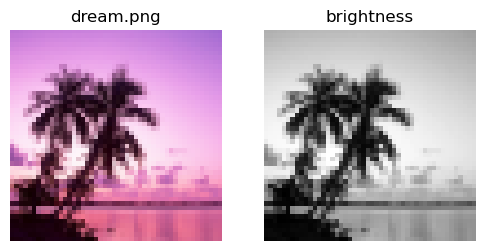

In [7]:
image = imread(os.path.join(DATA, "dream.png"))
print(image.shape, image.min(), image.max(), image.dtype)
scaled = image / 255.
print(scaled.min(), scaled.max(), scaled.dtype)
brightness = scaled.mean(axis=2)
flat_brightness = np.ravel(brightness)
print(brightness.shape, flat_brightness.shape)

fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].imshow(scaled); ax[0].set_title("dream.png")
ax[1].imshow(brightness, cmap="gray"); ax[1].set_title("brightness")
for a in ax: a.axis("off")
plt.show()

## Constructing the Image Graph

Each pixel $i$ has a brightness $B(i)$ and a location $X(i)$. Pixels within radius $r$ are joined by an edge with weight

$$w_{ij} = \exp\left(-\frac{|B(i)-B(j)|}{\sigma_B^2} - \frac{\|X(i)-X(j)\|}{\sigma_X^2}\right) \quad\text{if } \|X(i)-X(j)\| < r,$$

and $0$ otherwise. Nearby pixels of similar brightness are strongly connected, and contrasting pixels are weakly connected. The lab provides `get_neighbors()` to find the flattened indices of the pixels within radius $r$ of a central pixel, along with their distances.

In [8]:
def get_neighbors(index, radius, height, width):
    """Calculate the flattened indices of the pixels that are within the given
    distance of a central pixel, and their distances from the central pixel.

    Parameters:
        index (int): The index of a central pixel in a flattened image array
            with original shape (radius, height).
        radius (float): Radius of the neighborhood around the central pixel.
        height (int): The height of the original image in pixels.
        width (int): The width of the original image in pixels.

    Returns:
        (1-D ndarray): the indices of the pixels that are within the specified
            radius of the central pixel, with respect to the flattened image.
        (1-D ndarray): the euclidean distances from the neighborhood pixels to
            the central pixel.
    """
    # Calculate the original 2-D coordinates of the central pixel.
    row, col = index // width, index % width

    # Get a grid of possible candidates that are close to the central pixel.
    r = int(radius)
    x = np.arange(max(col - r, 0), min(col + r + 1, width))
    y = np.arange(max(row - r, 0), min(row + r + 1, height))
    X, Y = np.meshgrid(x, y)

    # Determine which candidates are within the given radius of the pixel.
    R = np.sqrt(((X - col)**2 + (Y - row)**2))
    mask = R < radius
    return (X[mask] + Y[mask]*width).astype(int), R[mask]


print(*get_neighbors(5, 1.2, 4, 4), sep="\n")
print(*get_neighbors(5, 1.5, 4, 4), sep="\n")

[1 4 5 6 9]
[1. 1. 0. 1. 1.]
[ 0  1  2  4  5  6  8  9 10]
[1.41421356 1.         1.41421356 1.         0.         1.
 1.41421356 1.         1.41421356]


---

## Problems 3-6: The `ImageSegmenter` Class

- **Problem 3:** The constructor reads and scales the image, computes its brightness (averaging all channels, including alpha for `blue_heart.png`), and stores the flattened brightness. `show_original()` displays the image.
- **Problem 4:** `adjacency()` builds $A$ as a `lil_matrix` one row at a time, then converts it to CSC. It also builds the degree vector $D$.
- **Problem 5:** `cut()` forms $D^{-1/2}LD^{-1/2}$ with sparse diagonal matrices and uses `eigsh(which="SM", k=2)` to get the eigenvector of the second-smallest eigenvalue. The sign of each entry gives the segment mask.
- **Problem 6:** `segment()` plots the original image, the positive segment, and the negative segment.

In [9]:
class ImageSegmenter:
    """Class for storing and segmenting images."""

    # Problem 3
    def __init__(self, filename):
        """Read the image file. Store its brightness values as a flat array."""
        self.image = imread(filename) / 255.
        self.color = self.image.ndim == 3
        self.brightness = self.image.mean(axis=2) if self.color else self.image
        self.m, self.n = self.brightness.shape
        self.flat_brightness = np.ravel(self.brightness)

    # Problem 3
    def show_original(self, ax=None):
        """Display the original image."""
        ax = ax or plt.gca()
        if self.color:
            ax.imshow(self.image)
        else:
            ax.imshow(self.image, cmap="gray")
        ax.axis("off")

    # Problem 4
    def adjacency(self, r=5., sigma_B2=.02, sigma_X2=3.):
        """Compute the Adjacency and Degree matrices for the image graph."""
        mn = self.m * self.n
        A = sparse.lil_matrix((mn, mn))
        D = np.empty(mn)
        B = self.flat_brightness
        for i in range(mn):
            J, dist = get_neighbors(i, r, self.m, self.n)
            weights = np.exp(-np.abs(B[i] - B[J]) / sigma_B2 - dist / sigma_X2)
            A[i, J] = weights
            D[i] = weights.sum()
        return A.tocsc(), D

    # Problem 5
    def cut(self, A, D):
        """Compute the boolean mask that segments the image."""
        L = csgraph.laplacian(A)
        D_mhalf = sparse.diags(1 / np.sqrt(D))
        M = D_mhalf @ L @ D_mhalf
        vals, vecs = spla.eigsh(M, which="SM", k=2)
        fiedler = vecs[:, np.argsort(vals)[1]]
        return fiedler.reshape((self.m, self.n)) > 0

    # Problem 6
    def segment(self, r=5., sigma_B2=.02, sigma_X2=3.):
        """Display the original image and its segments."""
        mask = self.cut(*self.adjacency(r, sigma_B2, sigma_X2))
        if self.color:
            mask = np.dstack([mask] * self.image.shape[2])
            show = lambda ax, img: ax.imshow(img)
        else:
            show = lambda ax, img: ax.imshow(img, cmap="gray")
        fig, ax = plt.subplots(1, 3, figsize=(10, 3.5))
        self.show_original(ax[0]); ax[0].set_title("Original")
        show(ax[1], self.image * mask); ax[1].set_title("Positive segment")
        show(ax[2], self.image * ~mask); ax[2].set_title("Negative segment")
        for a in ax: a.axis("off")
        plt.tight_layout()
        plt.show()

### Problem 3 check: `show_original()`

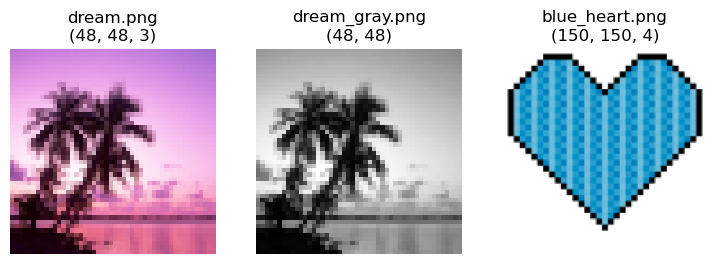

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for a, f in zip(ax, ["dream.png", "dream_gray.png", "blue_heart.png"]):
    seg = ImageSegmenter(os.path.join(DATA, f))
    seg.show_original(a)
    a.set_title(f"{f}\n{seg.image.shape}")
plt.show()

### Problem 4 check: compare against the reference heart matrices

`blue_heart.png` is $150\times150$ with an alpha channel, so the graph has $22{,}500$ nodes. The reference $A$ is stored as a sparse `.npz` file.

In [11]:
import time
heart = ImageSegmenter(os.path.join(DATA, "blue_heart.png"))
t0 = time.perf_counter()
A_heart, D_heart = heart.adjacency()
print(f"adjacency() built in {time.perf_counter() - t0:.2f} s")

A_ref = sparse.load_npz(os.path.join(DATA, "HeartMatrixA.npz"))
D_ref = np.load(os.path.join(DATA, "HeartMatrixD.npy"))
print("A shape:", A_heart.shape, " nnz:", A_heart.nnz)
print("A matches reference:", np.allclose((A_heart - A_ref).data, 0))
print("D matches reference:", np.allclose(D_heart, D_ref))

adjacency() built in 4.82 s
A shape: (22500, 22500)  nnz: 1511940
A matches reference: True
D matches reference: True


### Problem 6: segment `dream.png`

This should match Fig. 2 of the lab: one segment holds the figure and the other holds the background.

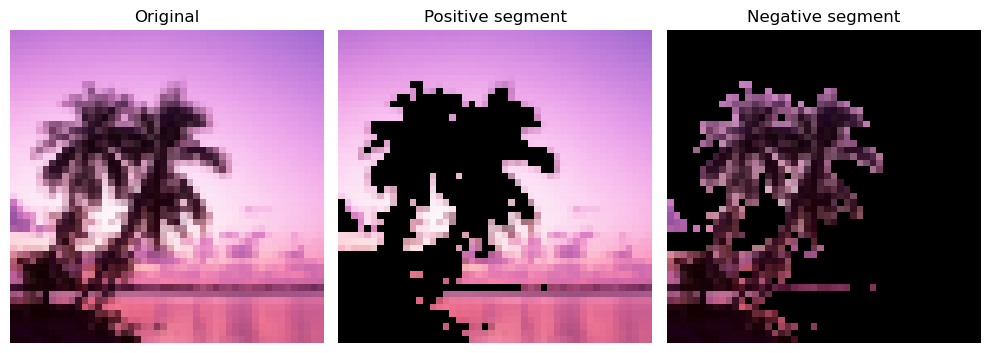

In [12]:
ImageSegmenter(os.path.join(DATA, "dream.png")).segment()

The segmenter works the same way on the grayscale version.

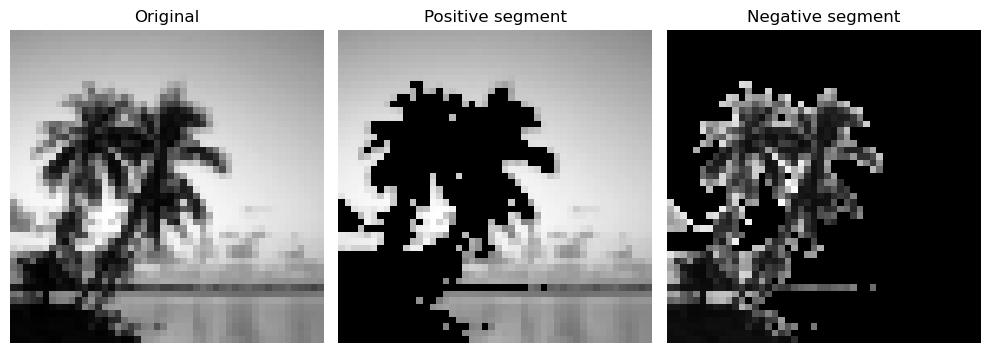

In [13]:
ImageSegmenter(os.path.join(DATA, "dream_gray.png")).segment()

### Segmenting the heart

ARPACK finds the largest eigenvalues of a matrix most readily, and `which="SM"` on a $22{,}500\times22{,}500$ matrix can take a long time. The normalized Laplacian's eigenvalues lie in $[0, 2]$, so the smallest eigenvalues of $M$ are the largest eigenvalues of $2I - M$, with the same eigenvectors. The cell below asks for those instead (`which="LA"`).

The sign of an eigenvector is arbitrary, so which segment is "positive" can flip between runs or solvers.

cut in 37.89 s


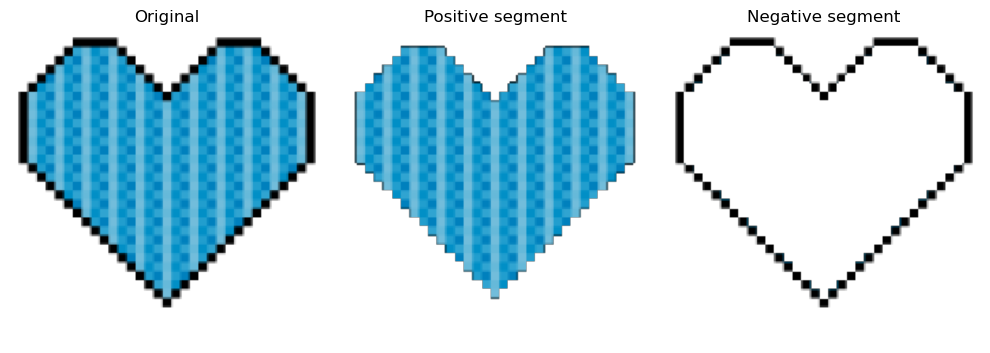

In [14]:
def fast_cut(seg, A, D):
    """Same as ImageSegmenter.cut(), but finds the small eigenpairs of M as
    the large eigenpairs of 2I - M."""
    L = csgraph.laplacian(A)
    D_mhalf = sparse.diags(1 / np.sqrt(D))
    M = D_mhalf @ L @ D_mhalf
    shifted = 2 * sparse.identity(M.shape[0], format="csc") - M
    vals, vecs = spla.eigsh(shifted, which="LA", k=2)
    fiedler = vecs[:, np.argsort(vals)[0]]   # 2nd largest of 2I-M = 2nd smallest of M
    return fiedler.reshape((seg.m, seg.n)) > 0

t0 = time.perf_counter()
mask = np.dstack([fast_cut(heart, A_heart, D_heart)] * 4)
print(f"cut in {time.perf_counter() - t0:.2f} s")

fig, ax = plt.subplots(1, 3, figsize=(10, 3.5))
heart.show_original(ax[0]); ax[0].set_title("Original")
ax[1].imshow(heart.image * mask); ax[1].set_title("Positive segment")
ax[2].imshow(heart.image * ~mask); ax[2].set_title("Negative segment")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## Discussion

- The Laplacian turns connectivity into an eigenvalue problem: the number of zero eigenvalues is the number of components, and the second-smallest eigenvalue measures how well connected the graph is.
- For an image graph, the Fiedler vector of the normalized Laplacian is a relaxed solution of the normalized-cut problem. Thresholding it at zero splits the pixels into two groups that are internally similar and weakly linked to each other.
- Because $r$ is small, $A$ has only about $\pi r^2$ nonzeros per row. Sparse storage and sparse eigensolvers are what make the method practical: the dense $22{,}500\times22{,}500$ heart matrix would need about 4 GB.